# 02 · Feature engineering

This notebook turns the clean tables from notebook 01 into model inputs. Run notebook 01 first.

| Section | Reads | Writes (in `data/processed/`) | Same for every split? | Time |
|---|---|---|---|---|
| 1. Tabular features | `tabular_clean/`, `data/splits/temporal_splits.csv` | `tabular_features/`, `tabular_features_folds/`, `feature_engineering_log.csv` | Partly: imputing and scaling are per split | ~30 s |
| 2. Sentiment + readability | `mda_clean/`, `data/sentiment/` | `text_features.parquet` | Yes | ~1 h |
| 3. Embeddings | `mda_clean/` | `text_embeddings.parquet` | Yes | Seconds if `text_embeddings_raw/` exists, else ~15 h |
| 4. TF-IDF | `mda_clean/`, `temporal_splits.csv` | `text_tfidf/split_<s>.parquet` | **No**, one file per split | ~5 min |

Three rules hold throughout:
1. Every file is keyed on `nodeID` + `Year`.
2. The text files have no `Label`. It comes from the tabular data.
3. Anything learned from data is learned from **training rows only**. That means per split, or from 2014, which is a training year in every split. So no test data leaks in.

In [1]:
from pathlib import Path
import re
import time

from matplotlib.colors import LinearSegmentedColormap
from sklearn.decomposition import PCA
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from transformers import AutoModel, AutoTokenizer
from transformers.utils import logging as hf_logging
import jieba.posseg as pseg
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import torch

/Users/tobiassurja/BT4012-Group14/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Works whether the notebook is run from notebook/ (Jupyter) or from the repo root.
ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
DATA_DIR = ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"
YEARS = range(2014, 2023)


# One chart style for the whole notebook (validated categorical palette, slots 1-3).
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK_2, GRID, MUTED = "#0b0b0b", "#52514e", "#e6e5e1", "#b8b7b1"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": INK_2, "ytick.color": INK_2, "font.size": 9.5,
    "legend.frameon": False, "lines.linewidth": 2,
})

# Figures are also saved to results/figures/ for the report and slides.
FIG_DIR = ROOT / "results" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)


def save_fig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")


## 1. Tabular features

**Step A: the same for every split.** Nothing is learned from the data here, so it's safe to compute once.
1. **Drop near-duplicates:** if two columns in the same group correlate above 0.95, keep the one with fewer gaps. Each drop is logged in `feature_engineering_log.csv`.
2. **Shrink huge values:** apply `sign(x) · log1p(|x|)` to every numeric column except longitude and latitude. Financial statement values reach 6e11, and some ratios reach millions when their denominator is near zero.
3. **Add year-over-year changes:** each company's value minus its own value last year.
4. **One-hot encode** the industry code.
5. **Add missing-value flags:** a `<col>_was_missing` column for each column with gaps, and one `is_first_year_on_record` flag.

**Step B: per split.** Fill the gaps with the median and scale the columns. Both are learned from that split's training rows only. A column whose spread is almost zero (below 0.01) is left unscaled, so tiny spreads can't turn normal values into millions.

Load the results with `pd.read_parquet("data/processed/tabular_features_folds/split_<s>")`.

In [3]:
TABFE_CLEAN_DIR = ROOT / "data" / "processed" / "tabular_clean"
TABFE_LOG_PATH = ROOT / "data" / "processed" / "cleaning_log.csv"
TABFE_SPLITS_PATH = ROOT / "data" / "splits" / "temporal_splits.csv"
TABFE_OUT_DIR = ROOT / "data" / "processed"
TABFE_FEATURES_DIR = TABFE_OUT_DIR / "tabular_features"
TABFE_FOLD_OUT_DIR = TABFE_OUT_DIR / "tabular_features_folds"

TABFE_KEYS = ["nodeID", "Year"]
TABFE_CORR_THRESHOLD = 0.95
# RobustScaler only guards against an *exactly* zero train-only IQR (replacing it with a
# scale of 1). A column that is mostly zero — e.g. a YoY delta for a ratio that rarely
# changes, made worse by median-imputing the first-year gaps to more zeros — can still
# get a train-only IQR of 1e-6 or smaller, which is effectively zero: dividing by it
# turns an ordinary value like 6.5 into millions. Flooring the scale extends the same
# "don't scale a near-constant column" guard to this near-zero case.
TABFE_MIN_SCALE = 1e-2


def load_clean() -> tuple[pd.DataFrame, pd.DataFrame]:
    clean = pd.read_parquet(TABFE_CLEAN_DIR)
    log = pd.read_csv(TABFE_LOG_PATH)
    return clean, log


def drop_correlated(df: pd.DataFrame, cols: list[str], missing: pd.Series, group: str) -> tuple[list[str], list[dict]]:
    """Within one feature group, drop a column when |corr| > 0.95 with some still-surviving column. 
    Pairs are resolved strongest-first, and a pair is only acted on while both members are still alive, 
    so every logged drop reflects a real correlation between the two named columns. 
    Never a transitive chain through some third column."""
    if len(cols) < 2:
        return [], []

    corr = df[cols].corr().abs().to_numpy()
    n = len(cols)
    pairs = [
        (corr[i, j], i, j)
        for i in range(n) for j in range(i + 1, n)
        if corr[i, j] > TABFE_CORR_THRESHOLD
    ]
    pairs.sort(key=lambda p: p[0], reverse=True)

    alive = [True] * n
    dropped, log_rows = [], []
    for r, i, j in pairs:
        if not (alive[i] and alive[j]):
            continue
        a, b = cols[i], cols[j]
        keep, drop, drop_idx = (a, b, j) if (missing[a], a) <= (missing[b], b) else (b, a, i)
        alive[drop_idx] = False
        dropped.append(drop)
        log_rows.append({
            "dropped_column": drop,
            "matched_column": keep,
            "correlation": round(float(r), 4),
            "group": group,
        })
    return dropped, log_rows


def engineer_fold_independent(clean: pd.DataFrame, log: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    kept_log = log[log["action"] == "kept"]
    groups = kept_log.set_index("column")["group"]
    missing = kept_log.set_index("column")["missing_clean"]
    numeric_cols = [c for c in kept_log["column"] if c != "IndustryCodeC"]

    df = clean[TABFE_KEYS + numeric_cols + ["IndustryCodeC"]].copy()

    all_dropped, all_log_rows = [], []
    for group in groups[numeric_cols].unique():
        cols_g = [c for c in numeric_cols if groups[c] == group]
        dropped, log_rows = drop_correlated(df, cols_g, missing, group)
        all_dropped += dropped
        all_log_rows += log_rows
    df = df.drop(columns=all_dropped)
    surviving_numeric = [c for c in numeric_cols if c not in all_dropped]

    # A dropped column's matched_column can itself go on to be dropped by something even more complete  
    # Resolve each drop to the column that actually survives in the output, without touching the logged correlation
    matched_of = {row["dropped_column"]: row["matched_column"] for row in all_log_rows}
    for row in all_log_rows:
        survivor = row["matched_column"]
        while survivor in matched_of:
            survivor = matched_of[survivor]
        row["survivor_column"] = survivor
    assert set(row["survivor_column"] for row in all_log_rows) <= set(surviving_numeric)

    # Originally applied only to the 4 monetary groups (balance sheet/income/cash flow),
    # on the assumption that "ratio / other" columns were already roughly bounded. That
    # assumption was wrong: some ratios have a near-zero denominator in a handful of
    # company-years and blow up to the millions (e.g. F040203B reaches 4.9e7 while its
    # median is ~5) — RobustScaler doesn't clip anything, so those points alone were
    # enough to break logistic regression's convergence. Apply the same taming transform
    # to every surviving numeric column except the two geographic ones, which aren't a
    # magnitude at all and don't have this problem.
    log_cols = [c for c in surviving_numeric if c not in ("RegisterLongitude", "RegisterLatitude")]
    df[log_cols] = np.sign(df[log_cols]) * np.log1p(df[log_cols].abs())

    # Sort before deriving anything else (YoY, missing-indicators) that depends on row order or gets concatenated back by position
    df = df.sort_values(TABFE_KEYS, ignore_index=True)

    # missing-indicators for the original columns before YoY adds its own structural NaNs
    incomplete = [c for c in surviving_numeric if df[c].isna().any()]
    indicators = df[incomplete].isna().astype(np.int8).add_suffix("_was_missing")

    # RegisterLongitude/RegisterLatitude are fixed facts about a company, not an evolving financial quantity 
    yoy_cols = [c for c in surviving_numeric if c not in ("RegisterLongitude", "RegisterLatitude")]
    yoy = df.groupby("nodeID")[yoy_cols].diff()
    yoy.columns = [f"{c}_yoy" for c in yoy_cols]

    is_first_year = (df.groupby("nodeID").cumcount() == 0).astype(np.int8)
    df = pd.concat([df, yoy, indicators, is_first_year.rename("is_first_year_on_record")], axis=1)

    industry = pd.get_dummies(df["IndustryCodeC"], prefix="industry", dtype=np.int8)
    df = pd.concat([df.drop(columns="IndustryCodeC"), industry], axis=1)

    float_cols = df.select_dtypes("float64").columns
    df[float_cols] = df[float_cols].astype(np.float32)

    feat_log = pd.DataFrame(
        all_log_rows, columns=["dropped_column", "matched_column", "correlation", "survivor_column", "group"]
    )
    return df, feat_log


def build_fold(s: int, splits: pd.DataFrame, features: pd.DataFrame) -> None:
    start = time.time()
    rows = splits.loc[splits["split"] == s, ["nodeID", "Year", "role"]]
    df = rows.merge(features, on=["nodeID", "Year"], how="left", validate="one_to_one")
    industry_cols = [c for c in df.columns if c.startswith("industry_")]
    assert (df[industry_cols].sum(axis=1) == 1).all(), "split row without engineered features"

    train = (df["role"] == "train").to_numpy()
    test_year = int(df.loc[~train, "Year"].min())
    assert df.loc[train, "Year"].max() < test_year, "a train row is not before the test year"

    feature_cols = [c for c in df.columns if c not in ("nodeID", "Year", "role")]
    imputer = SimpleImputer(strategy="median")
    x_train_imp = imputer.fit_transform(df.loc[train, feature_cols])
    x_all_imp = imputer.transform(df[feature_cols])

    scaler = RobustScaler()
    scaler.fit(x_train_imp)
    scaler.scale_[scaler.scale_ < TABFE_MIN_SCALE] = 1.0
    x_all_scaled = scaler.transform(x_all_imp).astype(np.float32)

    out = pd.concat(
        [df[["nodeID", "Year"]], pd.DataFrame(x_all_scaled, columns=feature_cols)], axis=1
    )

    split_dir = TABFE_FOLD_OUT_DIR / f"split_{s}"
    split_dir.mkdir(parents=True, exist_ok=True)
    total_bytes = 0
    for year, rows_y in out.groupby("Year"):
        path = split_dir / f"{year}.parquet"
        rows_y.to_parquet(path, index=False, compression="zstd")
        total_bytes += path.stat().st_size
    print(
        f"split {s}: train {int(train.sum()):,} rows (to {test_year - 1}), test {int((~train).sum()):,} rows ({test_year})  "
        f"features {len(feature_cols):,}  {total_bytes / 1e6:.1f} MB  {time.time() - start:.0f}s",
        flush=True,
    )

In [4]:
def run_build_tabular_features(split_ids: list[int]) -> None:
    clean, log = load_clean()
    features, feat_log = engineer_fold_independent(clean, log)

    kept_cols = [c for c in features.columns if c not in TABFE_KEYS]
    TABFE_FEATURES_DIR.mkdir(parents=True, exist_ok=True)
    for year, rows_y in features.groupby("Year"):
        rows_y.to_parquet(TABFE_FEATURES_DIR / f"{year}.parquet", index=False, compression="zstd")
    feat_log.to_csv(TABFE_OUT_DIR / "feature_engineering_log.csv", index=False)
    print(f"tabular_features: {features.shape[0]:,} rows, {len(kept_cols):,} columns")
    print(f"dropped {len(feat_log)} near-duplicate columns (|corr| > {TABFE_CORR_THRESHOLD})")
    print(f"wrote {TABFE_FEATURES_DIR.relative_to(ROOT)}/ and feature_engineering_log.csv")

    splits = pd.read_csv(TABFE_SPLITS_PATH)
    for s in split_ids or sorted(splits["split"].unique()):
        build_fold(s, splits, features)

In [5]:
run_build_tabular_features([])  # [] = all splits

tabular_features: 33,664 rows, 1,238 columns
dropped 196 near-duplicate columns (|corr| > 0.95)
wrote data/processed/tabular_features/ and feature_engineering_log.csv


split 0: train 15,679 rows (to 2018), test 3,815 rows (2019)  features 1,238  59.6 MB  3s


split 1: train 19,494 rows (to 2019), test 4,269 rows (2020)  features 1,238  73.3 MB  4s


split 2: train 23,763 rows (to 2020), test 4,769 rows (2021)  features 1,238  88.8 MB  5s


split 3: train 28,532 rows (to 2021), test 5,132 rows (2022)  features 1,238  105.6 MB  6s


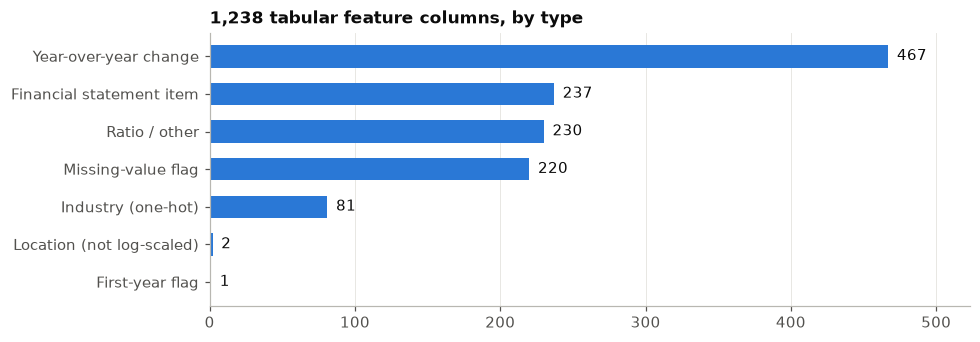

In [6]:
def plot_tabular_feature_types():
    cols = [c for c in pq.read_schema(TABFE_FEATURES_DIR / "2014.parquet").names if c not in TABFE_KEYS]
    groups = pd.read_csv(TABFE_LOG_PATH).set_index("column")["group"]

    def kind(c):
        if c.endswith("_yoy"):
            return "Year-over-year change"
        if c.endswith("_was_missing"):
            return "Missing-value flag"
        if c.startswith("industry_"):
            return "Industry (one-hot)"
        if c == "is_first_year_on_record":
            return "First-year flag"
        if c in ("RegisterLongitude", "RegisterLatitude"):
            return "Location (not log-scaled)"
        return "Financial statement item" if groups.get(c) in {"balance sheet", "income statement", "cash flow (direct)", "cash flow (indirect)"} else "Ratio / other"

    counts = pd.Series([kind(c) for c in cols]).value_counts().sort_values()
    fig, ax = plt.subplots(figsize=(9, 3.2))
    ax.barh(counts.index, counts.values, color=BLUE, height=0.6)
    for y, v in enumerate(counts.values):
        ax.text(v + 6, y, f"{v:,}", va="center", color=INK)
    ax.set_title(f"{len(cols):,} tabular feature columns, by type")
    ax.set_xlim(0, counts.max() * 1.12)
    ax.grid(axis="y", visible=False)
    fig.tight_layout()
    save_fig(fig, "fe_1_tabular_feature_types")
    plt.show()


plot_tabular_feature_types()

**Takeaway:** year-over-year changes are the largest group (467 of 1,238 columns). The rest are the cleaned originals, flags and industry codes.

## 2. Sentiment and readability features

These are six scores per report. Each is a share or a ratio, so long and cut-off reports are treated the same. Nothing is learned from the data, so one file serves every split. Reports with `has_text = 0` score 0 everywhere.

**Sentiment** counts words from the Yao et al. (2021) financial word lists:
1. Count the positive and negative words. A word in both lists is ignored.
2. Flip a word if 不, 没有, 未 or 无 comes up to 2 words before it. So 不 + 增长 counts as negative.
3. Divide by the total number of words to get `sent_pos` and `sent_neg`.
4. Combine them into `sent_tone = (pos − neg) / (pos + neg)`, which runs from −1 to +1.

**Readability** measures how hard the text is to read:
- `read_sent_len`: median words per sentence. 8 reports have almost no sentence punctuation, so they get the 2014 median instead.
- `read_complex`: share of words with 3 or more characters.
- `read_advconj`: share of adverbs and conjunctions, found by jieba's part-of-speech tagger. This tagger is the slow part (~1 h).

In [7]:
FEAT_CLEAN_DIR = ROOT / "data" / "processed" / "mda_clean"
FEAT_SENTIMENT_DIR = ROOT / "data" / "sentiment"

FEAT_NEGATIONS = {"不", "没有", "未", "无"}
FEAT_NEGATION_WINDOW = 2
FEAT_SENTENCE_END = {"。", "!", "?"}
FEAT_COMPLEX_MIN_CHARS = 3
# Fewer sentence endings than this (e.g. punctuation lost in the source) means sentence
# length can't be measured. Such rows get the median of FEAT_FILL_YEAR, which is in every
# walk-forward fold's training years, so the fill uses no validation or test data.
FEAT_MIN_SENTENCE_ENDS = 5
FEAT_FILL_YEAR = 2014
FEAT_PUNCT_ONLY = re.compile(r"^[\W_]+$")
FEAT_HAS_CJK = re.compile(r"[一-鿿]")

FEAT_FEATURES = [
    "sent_pos", "sent_neg", "sent_tone",
    "read_sent_len", "read_complex", "read_advconj",
]


def load_words(name: str) -> set[str]:
    path = FEAT_SENTIMENT_DIR / f"yao2021_formal_{name}.txt"
    return set(path.read_text(encoding="utf-8").split())


FEAT_POS_LIST, FEAT_NEG_LIST = load_words("pos"), load_words("neg")
# A word in both lists has no clear polarity, so it is ignored.
FEAT_POSITIVE, FEAT_NEGATIVE = FEAT_POS_LIST - FEAT_NEG_LIST, FEAT_NEG_LIST - FEAT_POS_LIST


def sentiment(tokens: list[str], total: int) -> tuple[float, float, float]:
    pos = neg = 0
    for i, word in enumerate(tokens):
        if word in FEAT_POSITIVE:
            polarity = 1
        elif word in FEAT_NEGATIVE:
            polarity = -1
        else:
            continue
        for j in range(i - 1, max(i - 1 - FEAT_NEGATION_WINDOW, -1), -1):
            if FEAT_PUNCT_ONLY.match(tokens[j]):
                break
            if tokens[j] in FEAT_NEGATIONS:
                polarity = -polarity
                break
        pos += polarity == 1
        neg += polarity == -1
    tone = (pos - neg) / (pos + neg) if pos + neg else 0.0
    return pos / total, neg / total, tone


def sentence_lengths(tokens: list[str]) -> list[int]:
    lengths, count = [], 0
    for word in tokens:
        if word in FEAT_SENTENCE_END:
            lengths.append(count)
            count = 0
        elif not FEAT_PUNCT_ONLY.match(word):
            count += 1
    lengths.append(count)
    return [n for n in lengths if n > 0]


def adverb_conjunction_share(text: str) -> float:
    total = hits = 0
    for pair in pseg.lcut(text):
        if pair.flag.startswith("x") or not pair.word.strip():
            continue
        total += 1
        hits += pair.flag[0] in "cd"
    return hits / total if total else 0.0


def report_features(args: tuple[int, str, str]) -> tuple[float, ...]:
    has_text, words, text_clean = args
    if not has_text:
        return (0.0,) * len(FEAT_FEATURES)
    tokens = words.split()
    content = [w for w in tokens if not FEAT_PUNCT_ONLY.match(w)]
    if not content:
        return (0.0,) * len(FEAT_FEATURES)
    pos, neg, tone = sentiment(tokens, len(content))
    cjk = [w for w in content if FEAT_HAS_CJK.search(w)]
    complex_share = sum(len(w) >= FEAT_COMPLEX_MIN_CHARS for w in cjk) / len(cjk) if cjk else 0.0
    ends = sum(w in FEAT_SENTENCE_END for w in tokens)
    sent_len = float(np.median(sentence_lengths(tokens))) if ends >= FEAT_MIN_SENTENCE_ENDS else np.nan
    return pos, neg, tone, sent_len, complex_share, adverb_conjunction_share(text_clean)

In [8]:
def run_build_text_features(years: list[int]) -> None:
    frames = []
    for year in years:
        start = time.time()
        df = pd.read_parquet(
            FEAT_CLEAN_DIR / f"{year}.parquet",
            columns=["nodeID", "Year", "has_text", "is_truncated", "words", "text_clean"],
        )
        rows = zip(df["has_text"], df["words"].fillna(""), df["text_clean"].fillna(""))
        scores = pd.DataFrame(
            list(map(report_features, rows)), columns=FEAT_FEATURES, index=df.index
        )
        frames.append(pd.concat([df[["nodeID", "Year", "has_text", "is_truncated"]], scores], axis=1))
        print(f"{year}: rows {len(df):,}  {time.time() - start:.0f}s")
    out = pd.concat(frames, ignore_index=True)
    unmeasurable = out["read_sent_len"].isna()
    print(f"read_sent_len unmeasurable (< {FEAT_MIN_SENTENCE_ENDS} sentence endings): "
          f"{int(unmeasurable.sum())} of {int((out.has_text == 1).sum()):,} rows with text")
    print("  by year:", out[unmeasurable].groupby("Year").size().to_dict())
    base = out[(out.Year == FEAT_FILL_YEAR) & (out.has_text == 1) & ~unmeasurable]
    if base.empty:
        print(f"  {FEAT_FILL_YEAR} not in this run: left as NaN")
    else:
        fill = float(base["read_sent_len"].median())
        out.loc[unmeasurable, "read_sent_len"] = fill
        print(f"  filled with the {FEAT_FILL_YEAR} median: {fill}")
    name = "text_features.parquet" if list(years) == list(YEARS) else "text_features_partial.parquet"
    path = ROOT / "data" / "processed" / name
    out.to_parquet(path, index=False)
    print(f"wrote {path.relative_to(ROOT)}  {len(out):,} rows  {path.stat().st_size / 1e6:.1f} MB")

In [9]:
run_build_text_features(list(YEARS))

Building prefix dict from the default dictionary ...


Loading model from cache /var/folders/bh/mys7kjrs6kbd5dmlndj0twv40000gn/T/jieba.cache


Loading model cost 0.301 seconds.


Prefix dict has been built successfully.


2014: rows 2,631  207s


2015: rows 2,824  179s


... (3 outputs left out)

2019: rows 3,815  294s


2020: rows 4,269  320s


2021: rows 4,769  497s


2022: rows 5,132  563s
read_sent_len unmeasurable (< 5 sentence endings): 8 of 33,148 rows with text
  by year: {2014: 1, 2015: 2, 2016: 1, 2017: 2, 2020: 1, 2021: 1}
  filled with the 2014 median: 29.0
wrote data/processed/text_features.parquet  33,664 rows  1.6 MB


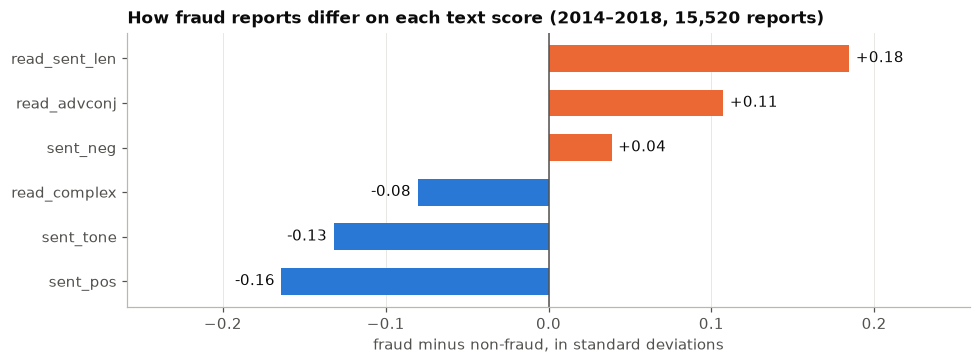

In [10]:
SCORES = ["sent_pos", "sent_neg", "sent_tone", "read_sent_len", "read_complex", "read_advconj"]


def load_text_scores():
    scores = pd.read_parquet(PROCESSED_DIR / "text_features.parquet")
    labels = pd.read_parquet(PROCESSED_DIR / "tabular_clean", columns=["nodeID", "Year", "Label"])
    return scores.merge(labels, on=["nodeID", "Year"])


def plot_scores_by_label():
    df = load_text_scores()
    df = df[(df["has_text"] == 1) & (df["Year"] <= 2018)]  # training years of split 0 only
    fraud, clean = df[df["Label"] == 1], df[df["Label"] == 0]
    # standardised difference: (fraud mean - non-fraud mean) / standard deviation of all reports
    diff = pd.Series({c: (fraud[c].mean() - clean[c].mean()) / df[c].std() for c in SCORES}).sort_values()

    fig, ax = plt.subplots(figsize=(9, 3.4))
    ax.barh(diff.index, diff.values, color=[ORANGE if v > 0 else BLUE for v in diff.values], height=0.6)
    for y, v in enumerate(diff.values):
        ax.text(v + (0.004 if v >= 0 else -0.004), y, f"{v:+.2f}", va="center",
                ha="left" if v >= 0 else "right", color=INK)
    ax.axvline(0, color=INK_2, linewidth=1)
    lim = max(abs(diff).max() * 1.4, 0.1)
    ax.set_xlim(-lim, lim)
    ax.set_xlabel("fraud minus non-fraud, in standard deviations")
    ax.set_title(f"How fraud reports differ on each text score (2014–2018, {len(df):,} reports)")
    ax.grid(axis="y", visible=False)
    fig.tight_layout()
    save_fig(fig, "fe_2_scores_by_label")
    plt.show()


plot_scores_by_label()

**Takeaway:** every difference is small, under 0.2 standard deviations.
- Fraud reports have longer sentences (`read_sent_len`, +0.18) and more adverbs and conjunctions (+0.11).
- They have less positive wording (`sent_pos`, −0.16) and a lower tone (−0.13).
- Negative wording barely differs (+0.04).

So no single score separates fraud from non-fraud. That's expected: these are inputs that the model combines, not detectors on their own.

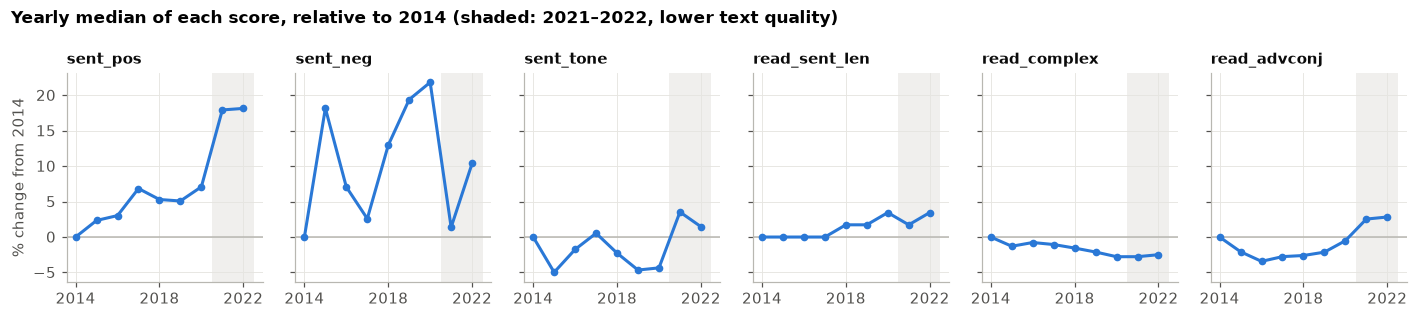

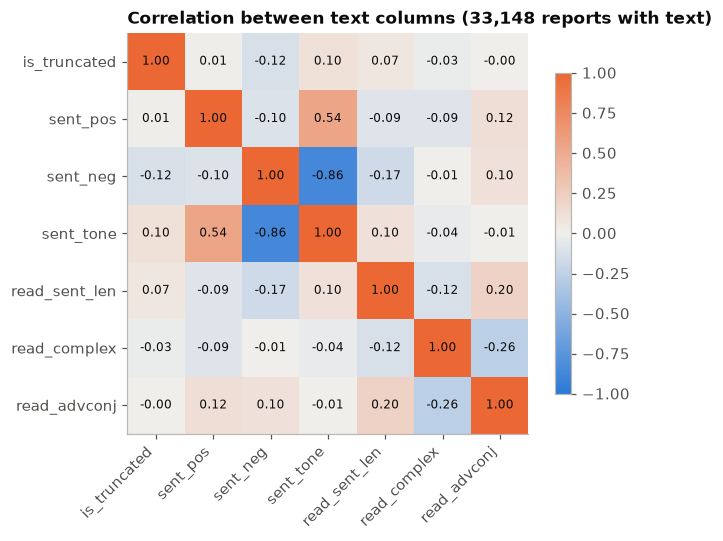

In [11]:
def plot_score_trends():
    df = load_text_scores()
    med = df[df["has_text"] == 1].groupby("Year")[SCORES].median()
    change = (med / med.loc[2014] - 1) * 100  # % change from 2014

    fig, axes = plt.subplots(1, 6, figsize=(13, 2.9), sharex=True, sharey=True)
    for ax, col in zip(axes, SCORES):
        ax.axvspan(2020.5, 2022.5, color=GRID, alpha=0.6, linewidth=0)
        ax.axhline(0, color=MUTED, linewidth=1)
        ax.plot(change.index, change[col], color=BLUE, marker="o", markersize=4)
        ax.set_title(col, fontsize=10)
        ax.set_xticks([2014, 2018, 2022])
    axes[0].set_ylabel("% change from 2014")
    fig.suptitle("Yearly median of each score, relative to 2014 (shaded: 2021–2022, lower text quality)",
                 x=0.01, ha="left", fontsize=11, fontweight="bold")
    fig.tight_layout()
    save_fig(fig, "fe_3_score_trends")
    plt.show()


def plot_text_feature_correlation():
    df = load_text_scores()
    df = df[df["has_text"] == 1]  # no-text rows are all 0 and would inflate every correlation
    cols = ["is_truncated"] + SCORES
    corr = df[cols].corr()
    cmap = LinearSegmentedColormap.from_list("div", [BLUE, "#f0efec", ORANGE])
    fig, ax = plt.subplots(figsize=(6.2, 5))
    im = ax.imshow(corr, cmap=cmap, vmin=-1, vmax=1)
    ax.set_xticks(range(len(cols)), cols, rotation=45, ha="right")
    ax.set_yticks(range(len(cols)), cols)
    for r in range(len(cols)):
        for c in range(len(cols)):
            ax.text(c, r, f"{corr.iloc[r, c]:.2f}", ha="center", va="center", fontsize=8, color=INK)
    ax.grid(False)
    ax.set_title(f"Correlation between text columns ({len(df):,} reports with text)")
    fig.colorbar(im, ax=ax, shrink=0.8)
    fig.tight_layout()
    save_fig(fig, "fe_4_text_correlation")
    plt.show()


plot_score_trends()
plot_text_feature_correlation()

**Takeaway:** on a shared scale, the readability scores barely move: all stay within ±4% of 2014.

The sentiment shares move more:
- Positive wording rises steadily, reaching about +18% in 2021–2022.
- Negative wording swings from year to year, by up to +22%.
- Tone moves less (±5%), because positive and negative wording rise together.

The 2021–2022 jump in positive wording matches the years with the most cut-off reports.

Among reports with text, the only strong links are inside the sentiment group, because `sent_tone` is built from `sent_pos` and `sent_neg` (−0.86 and 0.54). All other pairs are weak (at most 0.26), so the scores carry different information.

## 3. Embeddings

A pre-trained Chinese language model (`BAAI/bge-small-zh-v1.5`) turns each report into numbers that capture its meaning. This happens in two stages.

**Stage 1 (slow): embed.**
1. Split each report into chunks of 510 tokens, the most the model reads at once.
2. Turn each chunk into 512 numbers.
3. Average the chunks into one 512-number vector per report.

The results go to `text_embeddings_raw/` (gitignored). Years already done are skipped. So if all nine files exist, this stage takes no time; otherwise it takes ~15 h on a Mac GPU.

**Stage 2 (fast): compress.**
1. Fit PCA on 2014 only. 2014 is a training year in every split, so there's no leakage and one file serves every split.
2. Reduce each vector from 512 to 64 columns (`emb_0 … emb_63`).
3. Set the rows with `has_text = 0` to all zeros.

In [12]:
hf_logging.set_verbosity_error()

EMB_CLEAN_DIR = ROOT / "data" / "processed" / "mda_clean"
EMB_RAW_DIR = ROOT / "data" / "processed" / "text_embeddings_raw"
EMB_OUT = ROOT / "data" / "processed" / "text_embeddings.parquet"

EMB_MODEL = "BAAI/bge-small-zh-v1.5"
EMB_CHUNK_TOKENS = 510  # 512 limit minus [CLS] and [SEP]
EMB_BATCH = 256
EMB_N_COMPONENTS = 64
EMB_PCA_FIT_YEAR = 2014


# iian
if torch.cuda.is_available():
    EMB_DEVICE = "cuda"
elif torch.backends.mps.is_available():
    EMB_DEVICE = "mps"
else:
    EMB_DEVICE = "cpu"
EMB_DTYPE = torch.float16 if EMB_DEVICE == "cuda" else torch.float32
torch.set_num_threads(8)  # physical cores; only matters on the CPU fallback
# --

@torch.no_grad()
def embed(text: str, tok, model, device: str) -> np.ndarray:
    ids = tok(text, add_special_tokens=False)["input_ids"]
    pieces = [ids[i:i + EMB_CHUNK_TOKENS] for i in range(0, len(ids), EMB_CHUNK_TOKENS)]
    vecs = []
    for i in range(0, len(pieces), EMB_BATCH):
        batch = [[tok.cls_token_id] + p + [tok.sep_token_id] for p in pieces[i:i + EMB_BATCH]]
        enc = tok.pad({"input_ids": batch}, return_tensors="pt").to(device)
        # cls = model(**enc).last_hidden_state[:, 0]
        # iian
        cls = model(**enc).last_hidden_state[:, 0].float()
        # --
        vecs.append(torch.nn.functional.normalize(cls, dim=-1).cpu())
    return torch.cat(vecs).mean(0).numpy()


def embed_year(year: int, tok, model, device: str) -> None:
    start = time.time()
    df = pd.read_parquet(EMB_CLEAN_DIR / f"{year}.parquet", columns=["nodeID", "Year", "has_text", "text_clean"])
    dim = model.config.hidden_size
    vecs = np.zeros((len(df), dim), dtype=np.float32)
    for i, (has_text, text) in enumerate(zip(df["has_text"], df["text_clean"])):
        if has_text:
            vecs[i] = embed(text, tok, model, device)
        if (i + 1) % 500 == 0:
            print(f"  {year}: {i + 1:,}/{len(df):,}  {time.time() - start:.0f}s", flush=True)
    out = df[["nodeID", "Year", "has_text"]].reset_index(drop=True)
    out = pd.concat([out, pd.DataFrame(vecs, columns=[f"raw_{j}" for j in range(dim)])], axis=1)
    out.to_parquet(EMB_RAW_DIR / f"{year}.parquet", index=False)
    print(f"{year}: rows {len(df):,}  {time.time() - start:.0f}s", flush=True)


def compress() -> None:
    raw = pd.read_parquet(EMB_RAW_DIR)
    cols = [c for c in raw.columns if c.startswith("raw_")]
    fit_rows = (raw["Year"] == EMB_PCA_FIT_YEAR) & (raw["has_text"] == 1)
    pca = PCA(n_components=EMB_N_COMPONENTS, svd_solver="full").fit(raw.loc[fit_rows, cols].to_numpy())
    z = pca.transform(raw[cols].to_numpy()).astype(np.float32)
    z[raw["has_text"].to_numpy() == 0] = 0
    out = pd.concat(
        [raw[["nodeID", "Year"]], pd.DataFrame(z, columns=[f"emb_{j}" for j in range(EMB_N_COMPONENTS)])], axis=1
    )
    out.to_parquet(EMB_OUT, index=False)
    print(
        f"PCA fitted on {int(fit_rows.sum()):,} reports from {EMB_PCA_FIT_YEAR}: {EMB_N_COMPONENTS} components "
        f"explain {pca.explained_variance_ratio_.sum():.1%} of the variance"
    )
    print(f"wrote {EMB_OUT.relative_to(ROOT)}  {len(out):,} rows  {EMB_OUT.stat().st_size / 1e6:.1f} MB")
    return pca

In [13]:
def run_build_text_embeddings(years: list[int]) -> None:
    EMB_RAW_DIR.mkdir(parents=True, exist_ok=True)
    todo = [y for y in years if not (EMB_RAW_DIR / f"{y}.parquet").exists()]
    if todo:
        # device = "mps" if torch.backends.mps.is_available() else "cpu"
        tok = AutoTokenizer.from_pretrained(EMB_MODEL)
        tok.model_max_length = 10**9  # chunking is done here; silences the long-input warning

        # model = AutoModel.from_pretrained(EMB_MODEL).to(device).eval()
        # print(f"{EMB_MODEL} on {device}; years to embed: {todo}", flush=True)
        # for year in todo:
        #     embed_year(year, tok, model, device)

        # iian
        model = AutoModel.from_pretrained(EMB_MODEL, dtype=EMB_DTYPE).to(EMB_DEVICE).eval()
        print(f"{EMB_MODEL} on {EMB_DEVICE} ({EMB_DTYPE}); years to embed: {todo}", flush=True)
        for year in todo:
            embed_year(year, tok, model, EMB_DEVICE)
        # --
    if all((EMB_RAW_DIR / f"{y}.parquet").exists() for y in YEARS):
        return compress()
    else:
        missing = [y for y in YEARS if not (EMB_RAW_DIR / f"{y}.parquet").exists()]
        print(f"stage 2 waits for all years; missing: {missing}")

In [14]:
emb_pca = run_build_text_embeddings(list(YEARS))

PCA fitted on 2,583 reports from 2014: 64 components explain 77.2% of the variance
wrote data/processed/text_embeddings.parquet  33,664 rows  12.7 MB


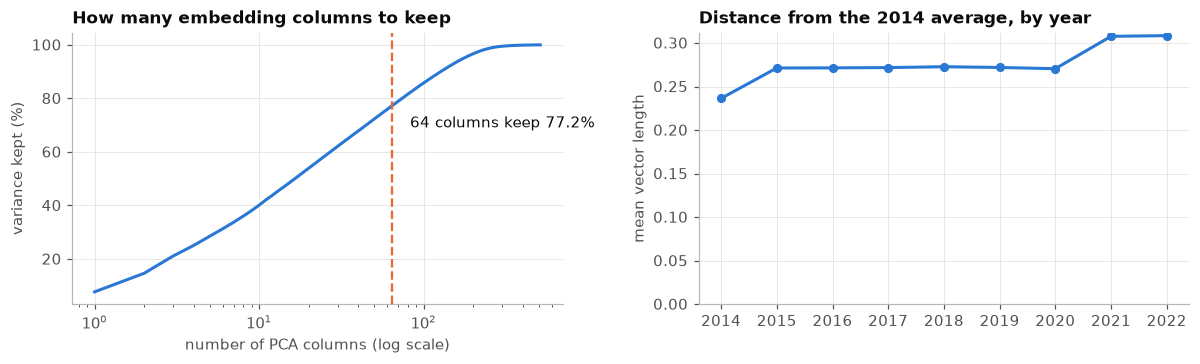

In [15]:
def plot_embedding_checks(pca):
    fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.4))
    if pca is not None:
        raw = pd.read_parquet(EMB_RAW_DIR / f"{EMB_PCA_FIT_YEAR}.parquet")
        raw = raw.loc[raw["has_text"] == 1, [c for c in raw.columns if c.startswith("raw_")]]
        full = PCA(svd_solver="full").fit(raw.to_numpy())
        cum = np.cumsum(full.explained_variance_ratio_) * 100
        a.plot(np.arange(1, len(cum) + 1), cum, color=BLUE)
        kept = cum[EMB_N_COMPONENTS - 1]
        a.axvline(EMB_N_COMPONENTS, color=ORANGE, linestyle="--", linewidth=1.5)
        a.annotate(f"{EMB_N_COMPONENTS} columns keep {kept:.1f}%", xy=(EMB_N_COMPONENTS, kept),
                   xytext=(12, -14), textcoords="offset points", color=INK)
        a.set_xscale("log")
        a.set_xlabel("number of PCA columns (log scale)")
        a.set_ylabel("variance kept (%)")
    a.set_title("How many embedding columns to keep")

    emb = pd.read_parquet(EMB_OUT)
    has_text = pd.read_parquet(PROCESSED_DIR / "text_features.parquet", columns=["nodeID", "Year", "has_text"])
    emb = emb.merge(has_text, on=["nodeID", "Year"])
    emb = emb[emb["has_text"] == 1]
    cols = [c for c in emb.columns if c.startswith("emb_")]
    norm = pd.Series(np.linalg.norm(emb[cols].to_numpy(), axis=1), index=emb["Year"]).groupby(level=0).mean()
    b.plot(norm.index, norm.values, color=BLUE, marker="o", markersize=5)
    b.set_ylim(0, None)
    b.set_ylabel("mean vector length")
    b.set_title("Distance from the 2014 average, by year")
    fig.tight_layout()
    save_fig(fig, "fe_5_embedding_checks")
    plt.show()


plot_embedding_checks(emb_pca)

**Takeaway:** 64 columns keep 77% of the information, while cutting the column count by 8×.

Later years sit further from the 2014 average, and the jump is in 2021–2022. This is the same shift seen in the text quality and the scores. It's expected, because PCA was fitted on 2014.

## 4. TF-IDF per split

TF-IDF describes which words a report uses. Each split gets its own version:

1. **Learn the vocabulary** from the split's **training rows only**. Keep words that appear in at least 5 reports but no more than half of them, which removes filler like 公司 and 年. Keep the 20,000 most common.
2. **Score each word** by how often the report uses it (log-scaled), weighted by how rare it is overall.
3. **Compress** the 20,000 scores into 100 topic columns with SVD, also learned from the training rows.
4. **Apply** both to the split's training and test rows.

Because each split learns its own vocabulary, the same report has different values in each file. So when training on split `s`, use `split_<s>.parquet` only.

In [16]:
TFIDF_CLEAN_DIR = ROOT / "data" / "processed" / "mda_clean"
TFIDF_SPLITS = ROOT / "data" / "splits" / "temporal_splits.csv"
TFIDF_OUT_DIR = ROOT / "data" / "processed" / "text_tfidf"

TFIDF_MIN_DF = 5          # word must appear in at least 5 train reports (drops typos, one-off names)
TFIDF_MAX_DF = 0.5        # drop words in more than half the train reports (finance filler)
TFIDF_MAX_FEATURES = 20_000
TFIDF_N_COMPONENTS = 100
TFIDF_SEED = 0


def load_tokens() -> pd.DataFrame:
    years = range(2014, 2023)
    cols = ["nodeID", "Year", "has_text", "tokens"]
    return pd.concat([pd.read_parquet(TFIDF_CLEAN_DIR / f"{y}.parquet", columns=cols) for y in years], ignore_index=True)


def build_split(s: int, splits: pd.DataFrame, docs: pd.DataFrame) -> None:
    start = time.time()
    rows = splits.loc[splits["split"] == s, ["nodeID", "Year", "role"]]
    df = rows.merge(docs, on=["nodeID", "Year"], how="left", validate="one_to_one")
    assert df["tokens"].notna().all(), "split row without an MD&A row"
    train = (df["role"] == "train").to_numpy()
    test_year = int(df.loc[~train, "Year"].min())
    assert df.loc[train, "Year"].max() < test_year

    vec = TfidfVectorizer(
        analyzer=str.split, min_df=TFIDF_MIN_DF, max_df=TFIDF_MAX_DF, max_features=TFIDF_MAX_FEATURES,
        sublinear_tf=True, dtype=np.float32,
    )
    x_train = vec.fit_transform(df.loc[train, "tokens"])
    x_all = vec.transform(df["tokens"])
    svd = TruncatedSVD(n_components=TFIDF_N_COMPONENTS, random_state=TFIDF_SEED).fit(x_train)
    z = svd.transform(x_all).astype(np.float32)

    no_text = (df["has_text"] == 0).to_numpy()
    assert np.abs(z[no_text]).sum() == 0, "has_text = 0 rows should be all zeros"
    out = pd.concat(
        [df[["nodeID", "Year"]], pd.DataFrame(z, columns=[f"tfidf_{j}" for j in range(TFIDF_N_COMPONENTS)])], axis=1
    )
    path = TFIDF_OUT_DIR / f"split_{s}.parquet"
    out.to_parquet(path, index=False)
    print(
        f"split {s}: train {int(train.sum()):,} rows (to {test_year - 1}), test {int((~train).sum()):,} rows ({test_year})  "
        f"vocab {len(vec.vocabulary_):,}  SVD keeps {svd.explained_variance_ratio_.sum():.1%}  "
        f"{path.stat().st_size / 1e6:.1f} MB  {time.time() - start:.0f}s",
        flush=True,
    )
    return vec, svd

In [17]:
def run_build_text_tfidf(split_ids: list[int]) -> None:
    TFIDF_OUT_DIR.mkdir(parents=True, exist_ok=True)
    splits = pd.read_csv(TFIDF_SPLITS)
    docs = load_tokens()
    return {s: build_split(s, splits, docs) for s in split_ids or sorted(splits["split"].unique())}

In [18]:
tfidf_models = run_build_text_tfidf([])  # [] = all splits

split 0: train 15,679 rows (to 2018), test 3,815 rows (2019)  vocab 20,000  SVD keeps 18.1%  11.5 MB  35s


split 1: train 19,494 rows (to 2019), test 4,269 rows (2020)  vocab 20,000  SVD keeps 18.1%  14.0 MB  43s


split 2: train 23,763 rows (to 2020), test 4,769 rows (2021)  vocab 20,000  SVD keeps 18.0%  16.7 MB  54s


split 3: train 28,532 rows (to 2021), test 5,132 rows (2022)  vocab 20,000  SVD keeps 18.5%  19.9 MB  69s


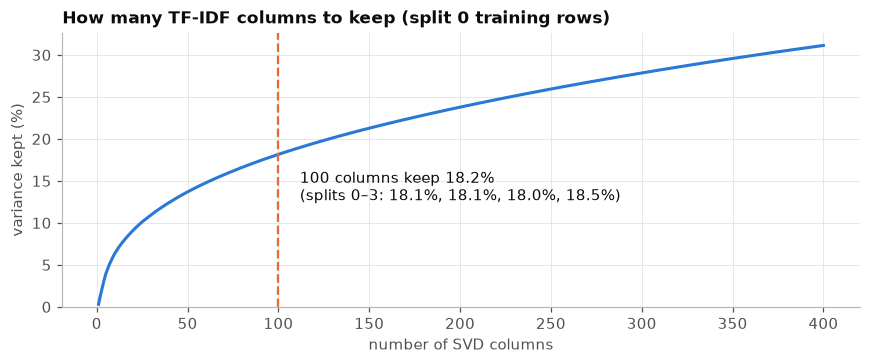

,tfidf_1,tfidf_2,tfidf_3,tfidf_4,tfidf_5
0,超募,药品,吨,利润分配,发电
1,募投,医药,利润分配,分红,电力
2,智能,临床,分红,转增,万千瓦
3,投向,药,万吨,含税,机组
4,可行性,医药行业,年产,公积金,电量
5,创业板,药业,工艺,预案,发电量
6,专户,药物,转增,会计准则,能源
7,置换,制剂,含税,股本,电网
8,自筹资金,治疗,预案,分配利润,电价
9,预先,制药,生产线,列报,电站


In [19]:
def plot_tfidf_variance(models, split=0, max_components=400):
    """Refit a larger SVD on split 0's training rows to show how variance grows with more columns."""
    splits = pd.read_csv(TFIDF_SPLITS)
    rows = splits.loc[(splits["split"] == split) & (splits["role"] == "train"), ["nodeID", "Year"]]
    docs = rows.merge(load_tokens(), on=["nodeID", "Year"])
    vec, _ = models[split]
    big = TruncatedSVD(n_components=max_components, random_state=TFIDF_SEED).fit(vec.transform(docs["tokens"]))
    cum = np.cumsum(big.explained_variance_ratio_) * 100
    kept = {s: svd.explained_variance_ratio_.sum() * 100 for s, (_, svd) in models.items()}

    fig, ax = plt.subplots(figsize=(8, 3.4))
    ax.plot(np.arange(1, max_components + 1), cum, color=BLUE)
    ax.axvline(TFIDF_N_COMPONENTS, color=ORANGE, linestyle="--", linewidth=1.5)
    ax.annotate(f"{TFIDF_N_COMPONENTS} columns keep {cum[TFIDF_N_COMPONENTS - 1]:.1f}%\n"
                f"(splits 0–3: {', '.join(f'{v:.1f}%' for v in kept.values())})",
                xy=(TFIDF_N_COMPONENTS, cum[TFIDF_N_COMPONENTS - 1]), xytext=(14, -30),
                textcoords="offset points", color=INK)
    ax.set_xlabel("number of SVD columns")
    ax.set_ylabel("variance kept (%)")
    ax.set_ylim(0, None)
    ax.set_title(f"How many TF-IDF columns to keep (split {split} training rows)")
    fig.tight_layout()
    save_fig(fig, "fe_6_tfidf_variance")
    plt.show()


def top_words(models, split=0, components=range(1, 6), n=10):
    vec, svd = models[split]
    names = vec.get_feature_names_out()
    return pd.DataFrame({f"tfidf_{k}": names[np.argsort(-svd.components_[k])[:n]] for k in components})


plot_tfidf_variance(tfidf_models)
top_words(tfidf_models)

**Takeaway:** the curve flattens early. After the first ~25 columns, each extra column adds little.
- 100 columns keep about 18% of the variation. That's normal for TF-IDF, because word counts are sparse and noisy.
- Four times as many columns (400) would only reach about 31%.
- The four splits keep almost the same share (18.0–18.5%), so the choice works for all of them.

The top words show the columns are real topics, for example:
- IPO proceeds (超募, 募投)
- pharma (药品, 临床)
- dividends (利润分配, 分红)
- power (发电, 电网)

## 5. Summary of model inputs

This table lists every feature group this notebook produces. It joins on `nodeID` + `Year`, and `Label` comes from the tabular data.

In [20]:
def feature_overview():
    tab_cols = [c for c in pq.read_schema(TABFE_FEATURES_DIR / "2014.parquet").names if c not in TABFE_KEYS]
    groups = pd.read_csv(TABFE_LOG_PATH).set_index("column")["group"]
    count = lambda pred: sum(pred(c) for c in tab_cols)
    is_orig = lambda c: not c.endswith(("_yoy", "_was_missing")) and not c.startswith("industry_") and c != "is_first_year_on_record"
    rows = [
        ("Tabular: financial statements", "numeric, log-scaled", count(lambda c: is_orig(c) and groups.get(c) in {"balance sheet", "income statement", "cash flow (direct)", "cash flow (indirect)"}),
         "Balance sheet, income and cash flow items", "imputed + scaled per split", "tabular_features_folds/split_<s>/"),
        ("Tabular: ratios and other", "numeric, log-scaled (except location)", count(lambda c: is_orig(c) and groups.get(c) not in {"balance sheet", "income statement", "cash flow (direct)", "cash flow (indirect)"}),
         "Financial ratios, location", "imputed + scaled per split", "tabular_features_folds/split_<s>/"),
        ("Tabular: year-over-year change", "numeric", count(lambda c: c.endswith("_yoy")),
         "Change from the company's previous year", "imputed + scaled per split", "tabular_features_folds/split_<s>/"),
        ("Tabular: flags", "binary 0/1", count(lambda c: c.endswith("_was_missing") or c == "is_first_year_on_record"),
         "Value was missing / company's first year", "imputed + scaled per split", "tabular_features_folds/split_<s>/"),
        ("Tabular: industry", "binary 0/1 (one-hot)", count(lambda c: c.startswith("industry_")),
         "Industry code", "imputed + scaled per split", "tabular_features_folds/split_<s>/"),
        ("Text flags", "binary 0/1", 2, "has_text, is_truncated", "same for all splits", "text_features.parquet"),
        ("Sentiment", "numeric, share or −1…1", 3, "sent_pos, sent_neg, sent_tone", "same for all splits", "text_features.parquet"),
        ("Readability", "numeric", 3, "read_sent_len, read_complex, read_advconj", "same for all splits", "text_features.parquet"),
        ("Embeddings", "numeric", EMB_N_COMPONENTS, "Meaning of the report (language model + PCA on 2014)",
         "same for all splits", "text_embeddings.parquet"),
        ("TF-IDF topics", "numeric", TFIDF_N_COMPONENTS, "Word-usage topics", "**fitted per split**", "text_tfidf/split_<s>.parquet"),
    ]
    out = pd.DataFrame(rows, columns=["group", "type", "columns", "meaning", "fitting", "file (data/processed/)"])
    out.loc[len(out)] = ["Total per split", "", out["columns"].sum(), "", "", ""]
    return out


feature_overview()

,group,type,columns,meaning,fitting,file (data/processed/)
0,Tabular: financial statements,"numeric, log-scaled",237,"Balance sheet, income and cash flow items",imputed + scaled per split,tabular_features_folds/split_<s>/
1,Tabular: ratios and other,"numeric, log-scaled (except location)",232,"Financial ratios, location",imputed + scaled per split,tabular_features_folds/split_<s>/
2,Tabular: year-over-year change,numeric,467,Change from the company's previous year,imputed + scaled per split,tabular_features_folds/split_<s>/
3,Tabular: flags,binary 0/1,221,Value was missing / company's first year,imputed + scaled per split,tabular_features_folds/split_<s>/
4,Tabular: industry,binary 0/1 (one-hot),81,Industry code,imputed + scaled per split,tabular_features_folds/split_<s>/
5,Text flags,binary 0/1,2,"has_text, is_truncated",same for all splits,text_features.parquet
6,Sentiment,"numeric, share or −1…1",3,"sent_pos, sent_neg, sent_tone",same for all splits,text_features.parquet
7,Readability,numeric,3,"read_sent_len, read_complex, read_advconj",same for all splits,text_features.parquet
8,Embeddings,numeric,64,Meaning of the report (language model + PCA on...,same for all splits,text_embeddings.parquet
9,TF-IDF topics,numeric,100,Word-usage topics,**fitted per split**,text_tfidf/split_<s>.parquet
